# 11 · Real against drawn

The set is mostly recorded (notebook 0): screen captures from YouTube-8M's computer categories
(kind `screen`, mostly 24-30 fps) and other video at 50-60 fps (`video`), beside drawn scenes
(`page`, `desktop`, `photo`) - a still picture moved by whole pixels, the tile search's own model of
the world. A score over the whole set mixes them. This notebook splits every method's score by
kind and by frame rate, and asks of each kind the question the drawn scenes cannot answer for
the recordings: **is there motion to find, and does the tile search find it?**

Steps:

1. **The validation set by kind** - sources, videos, frame rates, tiles; and how many received
   frames the recordings lose to repeated frames (`runs.valid`).
2. **Scores by kind** - notebook 10's and notebook 9's validation runs split by kind.
3. **What moves** - on every changed tile: the true motion from N to N+1 (searched with N+1 in hand,
   one per tile and per 16 px block), whether it is a motion at all, and how often the tile
   search's motion is right.
4. **Examples** - per kind, the changed tile at the median of the tile search's score.

Needs: notebooks 9 and 10's validation caches. Nothing is trained or exported; cached in
`checkpoints/recorded/`.

In [1]:
"""Settings."""

import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import clips, history, models, runs, show, training
from helpers.training import DEVICE, to_tensor
from helpers.webexport import TILE_INPUT

STILL, SHARPNESS, CAP = 0.1, 10.0, 50.0
CACHE = training.CHECKPOINT_DIR / "recorded"
SEED = 0
KINDS = ("page", "desktop", "photo", "screen", "video")
manifest = training.load_manifest()
training.describe(manifest)
RECEIVED = runs.received_every(manifest)
sources = manifest["splits"]["val"]["sources"]
published = models.TileSearch(4, 2, SHARPNESS, 2, 1 / RECEIVED, still=STILL).to(DEVICE).eval()
search_model = models.Motion(search=published, learned=False).to(DEVICE).eval()
val10 = pickle.loads((training.CHECKPOINT_DIR / "masked" / "val.pkl").read_bytes())
val9 = pickle.loads((training.CHECKPOINT_DIR / "recursive" / "val.pkl").read_bytes())


def kinds_of(found):
    return np.array([sources[s]["kind"] for s in found["tiles"]["source"]])


def video_of(found):
    return np.array([sources[s].get("video", sources[s]["file"]) for s in found["tiles"]["source"]])

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)


## 1. The validation set by kind

Per kind: sources, distinct videos (a recording's five clips share one), frame rates, and the client
tiles every method is scored on (every received frame from N = 6, as notebooks 9 and 10). For the
recordings, the share of received frames dropped because the frames around them repeat - a
recorder capturing slower than its video's rate.

In [2]:
tiles = val10["tiles"]
kind = kinds_of(val10)
print(f"{'kind':<10}{'sources':>9}{'videos':>8}{'rates (fps)':>18}{'tiles':>8}{'moving':>8}{'changed':>9}{'frames dropped':>16}")
for k in KINDS:
    chosen = [s for s in sources if s["kind"] == k]
    rates = sorted({round(s["fps"]) for s in chosen})
    videos = len({s.get("video", s["file"]) for s in chosen})
    dropped = total = 0
    for s in chosen:
        if "steps" not in s:
            continue
        frames = len(s["steps"]) + 1
        for n in range(RECEIVED, frames - 1, RECEIVED):
            total += 1
            dropped += not runs.valid(s, n, RECEIVED)
    m = kind == k
    print(f"{k:<10}{len(chosen):9}{videos:8}{str(rates):>18}{m.sum():8}{tiles['moving'][m].mean():8.0%}"
          f"{tiles['changed'][m].mean():9.0%}" + (f"{dropped / total:16.0%}" if total else f"{'-':>16}"))

kind        sources  videos       rates (fps)   tiles  moving  changed  frames dropped
page             28      28              [60]    3024     56%      43%               -
desktop          12      12              [60]    1296     20%      14%               -
photo            15      15              [60]    1620     81%      59%               -
screen          144      30          [25, 30]    9227     43%      18%             17%
video            33       9          [50, 60]    2023     91%      72%             17%


## 2. Scores by kind

Notebook 10's validation run (repeat, the published search, the pyramid, the fallback to N where
the search is unsure, the masked network) and notebook 9's (3DRS, beside its own published search -
x264 does not encode a clip the same way twice, so each run is compared within itself). Absolute
wPSNR on the changed tiles and on the moving ones capped at 50 dB, per kind, with every kind's tile
count; then the published search's gain over repeat per kind with its 95% range over videos.

In [3]:
rng = np.random.default_rng(SEED)


def over(gain, mask, groups, draws=2000):
    per = [gain[mask & (groups == g)] for g in np.unique(groups[mask])]
    means = [np.concatenate([per[i] for i in rng.integers(0, len(per), len(per))]).mean() for _ in range(draws)]
    return np.percentile(means, [2.5, 97.5])


def by_kind(found, names, title):
    t, w = found["tiles"], found["wpsnr"]
    k, changed, moving = kinds_of(found), t["changed"], t["moving"]
    for label, mask, cap in (("changed tiles", changed, False), ("moving tiles, ≤ 50 dB", moving, True)):
        print(f"\n{title}: {label}")
        print(f"{'':<36}" + "".join(f"{x:>10}" for x in (*KINDS, "all")))
        print(f"{'tiles':<36}" + "".join(f"{(mask & (k == x)).sum():10}" for x in KINDS) + f"{mask.sum():10}")
        for name in names:
            s = np.minimum(w[name], CAP) if cap else w[name]
            print(f"{name:<36}" + "".join(f"{s[mask & (k == x)].mean():10.2f}" for x in KINDS) + f"{s[mask].mean():10.2f}")


by_kind(val10, ["repeat", "published search", "pyramid, whole-pixel (notebook 8)",
                *[n for n in val10["wpsnr"] if n.startswith("fallback")], "masked, gated"], "notebook 10's run")
by_kind(val9, ["repeat", "published search", "3DRS", "full search, 8 px, ±16 px"], "notebook 9's run")

k, v, t = kinds_of(val10), video_of(val10), val10["tiles"]
gain = val10["wpsnr"]["published search"] - val10["wpsnr"]["repeat"]
print(f"\nthe published search over repeat, changed tiles, 95% over videos (clips for the drawn kinds):")
for x in KINDS:
    m = t["changed"] & (k == x)
    low, high = over(gain, m, v)
    print(f"  {x:<10}{gain[m].mean():+6.2f} dB  [{low:+.2f}, {high:+.2f}]  ({len(set(v[m]))} videos or clips)")
rate = np.array([sources[s]["fps"] for s in t["source"]])
for label, m in (("recorded, 24-30 fps", (rate < 40) & np.isin(k, ("screen", "video"))),
                 ("recorded, 50-60 fps", (rate >= 40) & np.isin(k, ("screen", "video"))),
                 ("drawn, 60 fps", np.isin(k, ("page", "desktop", "photo")))):
    m = m & t["changed"]
    print(f"  {label:<22} repeat {val10['wpsnr']['repeat'][m].mean():6.2f}, search {val10['wpsnr']['published search'][m].mean():6.2f} "
          f"dB on {m.sum()} changed tiles")


notebook 10's run: changed tiles
                                          page   desktop     photo    screen     video       all
tiles                                     1310       184       955      1652      1452      5553
repeat                                   24.69     29.30     23.49     32.39     30.13     28.35
published search                         29.32     29.33     31.06     34.17     30.85     31.46
pyramid, whole-pixel (notebook 8)        30.23     29.07     30.47     33.57     30.88     31.40
fallback: N where u > 0.95               29.17     29.44     30.78     34.23     31.18     31.49
masked, gated                            28.99     29.58     30.74     34.15     31.21     31.43

notebook 10's run: moving tiles, ≤ 50 dB
                                          page   desktop     photo    screen     video       all
tiles                                     1681       264      1310      3990      1840      9085
repeat                                   31.29     

## 3. What moves

On every changed validation tile (N+1 differs from N), the motion from N to N+1 searched with N+1
in hand - one whole-pixel offset for the tile within ±16 px, and one per 16 px block within ±12
(`models.Shift`, notebook 7's oracle). Neither can be built - the client never has N+1 - but they
say how much of a kind's change is motion at all, and how much of it the tile search finds: it
carries half the motion it found between N−2 and N, which should be the true motion to N+1 if the
content moves steadily.

In [4]:
tile_truth = models.Shift(radius=16, block=None).to(DEVICE)
block_truth = models.Shift(radius=12, block=16).to(DEVICE)


@torch.no_grad()
def what_moves(index):
    source = sources[index]
    stream = clips.rebuild(source, manifest)
    layout, size = clips.plan(stream.shape[2], stream.shape[1])
    if size != TILE_INPUT:
        return []
    chosen = []
    for n in range(3 * RECEIVED, len(stream) - 1, RECEIVED):
        if not runs.valid(source, n, RECEIVED):
            continue
        for t, (ix, iy, ox, oy, w, h) in enumerate(layout):
            if runs.changed_share(stream[n, iy + oy:iy + oy + h, ix + ox:ix + ox + w],
                                  stream[n + 1, iy + oy:iy + oy + h, ix + ox:ix + ox + w]) >= runs.MOVING_SHARE:
                chosen.append((n, t))
    rows = []
    for first in range(0, len(chosen), 32):
        batch = chosen[first:first + 32]
        windows = np.stack([stream[[n - RECEIVED, n, n + 1], layout[t][1]:layout[t][1] + size[0],
                                   layout[t][0]:layout[t][0] + size[1]] for n, t in batch])
        previous, current, target = to_tensor(windows).unbind(1)
        motion, zero, _ = published.measure(previous, current)
        carried = motion * (zero >= STILL)[:, None] / RECEIVED
        tile_field = tile_truth.field(current, target)
        made = {"repeat": current, "search": search_model(previous, current),
                "true motion, per tile": models.warp(current, tile_field),
                "true motion, per block": models.warp(current, block_truth.field(current, target))}
        for i, (n, t) in enumerate(batch):
            box = (layout[t][3], layout[t][2], layout[t][5], layout[t][4])
            truth = clips.kept(target[i:i + 1], box)
            scores = [float(history.sample_wpsnr(clips.kept(p[i:i + 1], box), truth)[0]) for p in made.values()]
            rows.append([*scores, *carried[i].tolist(), *(-tile_field[i, :, 0, 0]).tolist(), index, n, t])
    return rows


path = CACHE / "what_moves.pkl"
CACHE.mkdir(parents=True, exist_ok=True)
if path.exists() and path.stat().st_mtime > (training.DATA_DIR / "manifest.json").stat().st_mtime:
    moves = pickle.loads(path.read_bytes())
else:
    started, moves = time.time(), {x: [] for x in KINDS}
    for index, source in enumerate(sources):
        moves[source["kind"]] += what_moves(index)
    moves = {x: np.array(rows) for x, rows in moves.items()}
    path.write_bytes(pickle.dumps(moves))
    print(f"{sum(len(r) for r in moves.values())} changed tiles in {time.time() - started:.0f}s")

print(f"{'changed tiles':<44}" + "".join(f"{x:>10}" for x in KINDS))
print(f"{'tiles':<44}" + "".join(f"{len(moves[x]):10}" for x in KINDS))
for i, name in enumerate(("repeat", "tile search", "true motion, one per tile", "true motion, per 16 px block")):
    print(f"{name + ' (wPSNR)':<44}" + "".join(f"{moves[x][:, i].mean():10.2f}" for x in KINDS))
stats = {}
for x in KINDS:
    a = moves[x]
    carried, true = a[:, 4:6], a[:, 6:8]
    moving = np.linalg.norm(true, axis=1) >= 1
    along = np.where(moving, (carried * true).sum(1) / np.maximum((true * true).sum(1), 1e-9), 0)
    stats[x] = {"a whole-tile motion of 1 px or more": moving.mean(),
                "  of those, the search carries it (0.75-1.25x)": ((along > 0.75) & (along < 1.25))[moving].mean(),
                "  about half of it (0.25-0.75x)": ((along >= 0.25) & (along <= 0.75))[moving].mean(),
                "  nothing, or the wrong way (< 0.25x)": (along < 0.25)[moving].mean(),
                "  faster than 4 px a frame": (np.linalg.norm(true, axis=1) > 4)[moving].mean()}
for row in stats[KINDS[0]]:
    print(f"{row:<44}" + "".join(f"{stats[x][row]:10.0%}" for x in KINDS))

5553 changed tiles in 211s
changed tiles                                     page   desktop     photo    screen     video
tiles                                             1313       184       952      1649      1455
repeat (wPSNR)                                   24.75     29.30     23.39     32.35     30.16
tile search (wPSNR)                              29.37     29.33     31.00     34.14     30.86
true motion, one per tile (wPSNR)                35.74     30.59     33.20     34.88     32.51
true motion, per 16 px block (wPSNR)             35.79     39.31     34.81     37.79     36.32
a whole-tile motion of 1 px or more                76%       32%       81%       26%       51%
  of those, the search carries it (0.75-1.25x)       35%        2%       58%       48%       36%
  about half of it (0.25-0.75x)                    16%       22%       19%       24%       38%
  nothing, or the wrong way (< 0.25x)              33%       71%        5%       24%       20%
  faster than 4 px a 

## 4. Examples

Per kind, among the changed validation tiles of section 3, the one at the median of the tile
search's score - typical, not chosen (rebuilt, so the codec's pictures differ by a level or so). Rows: the received frames and N+1; what repeat, the tile
search and the true per-block motion (which sees N+1) make; their errors (black right, yellow 48
luma levels or more wrong).

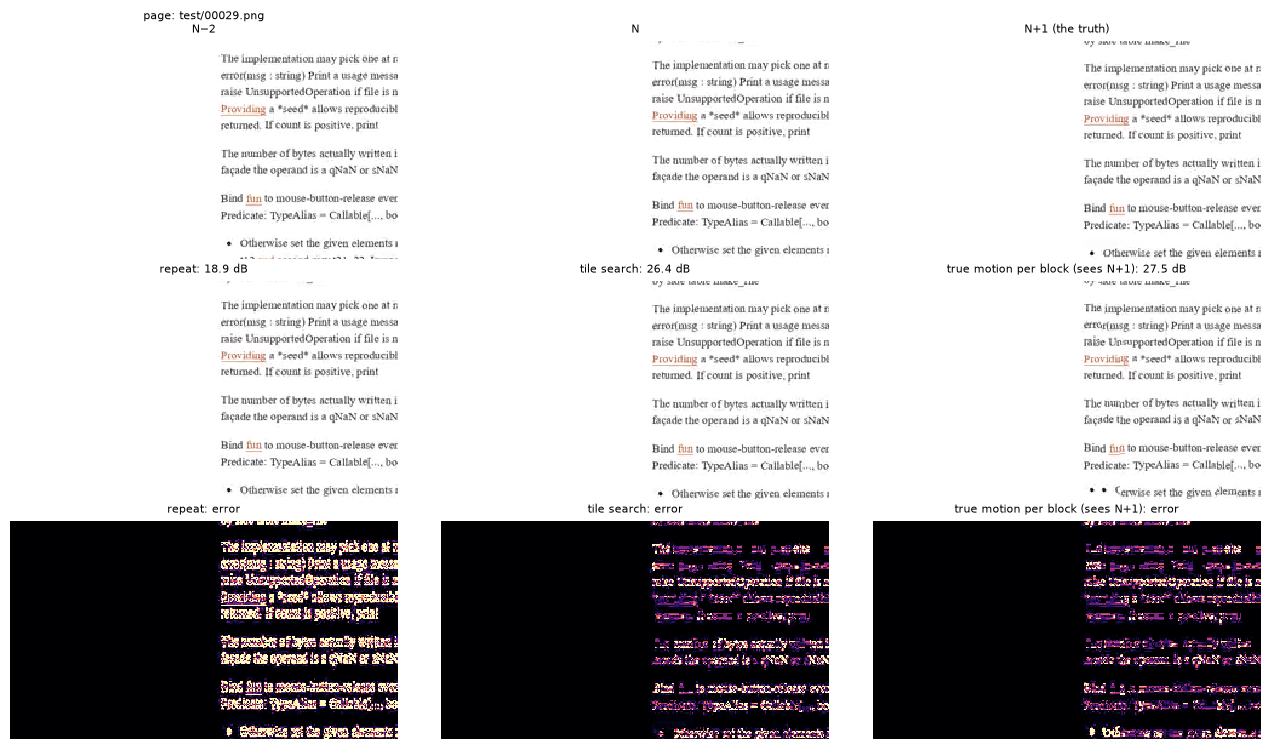

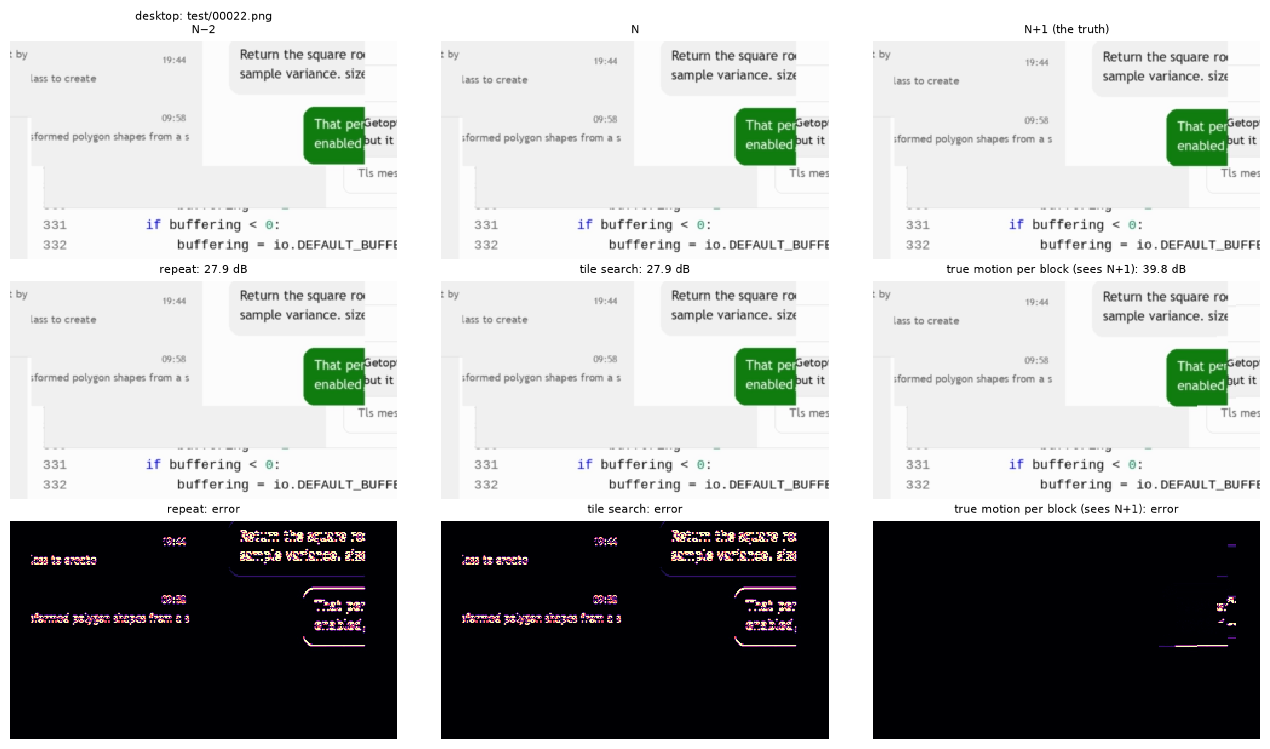

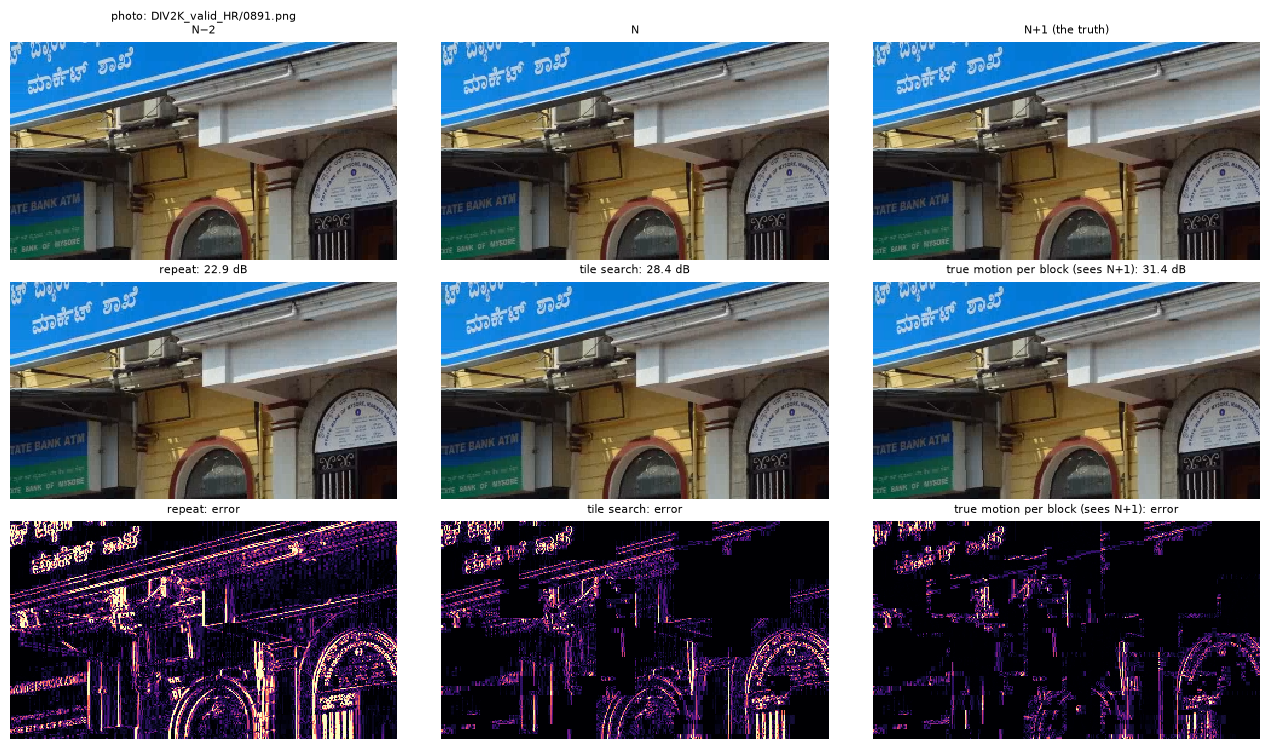

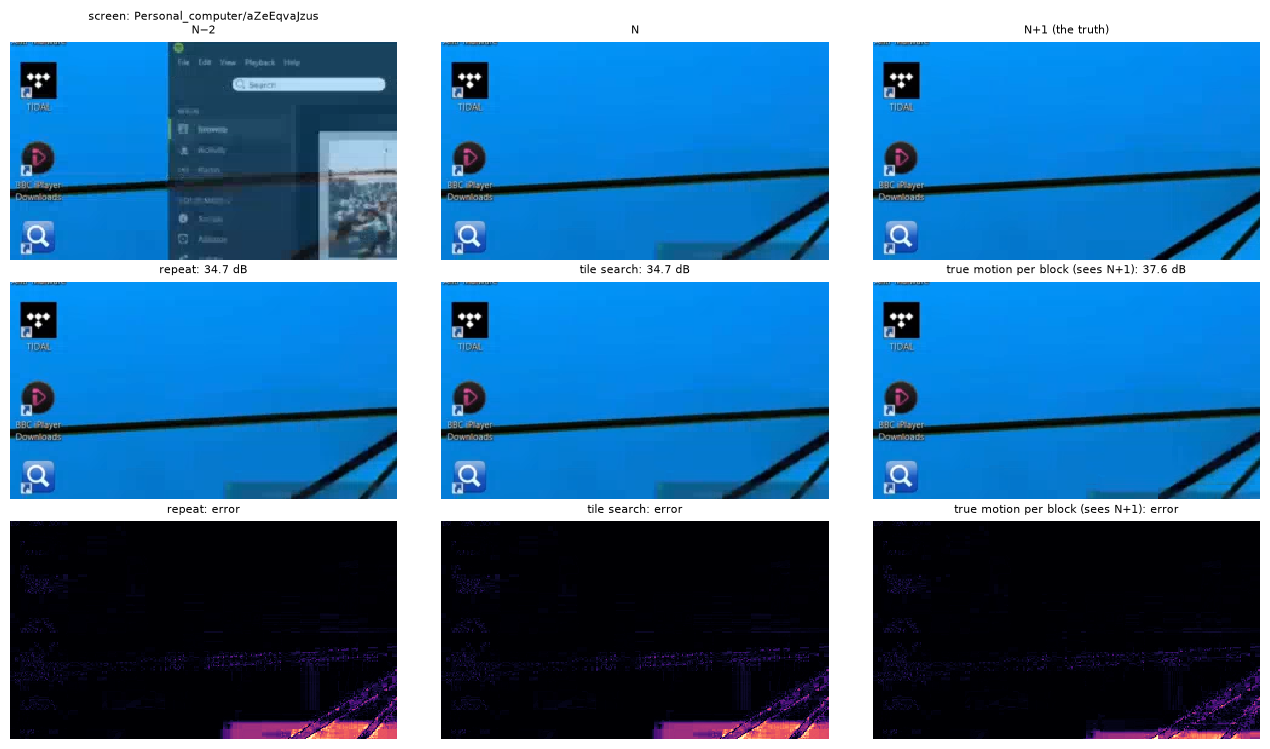

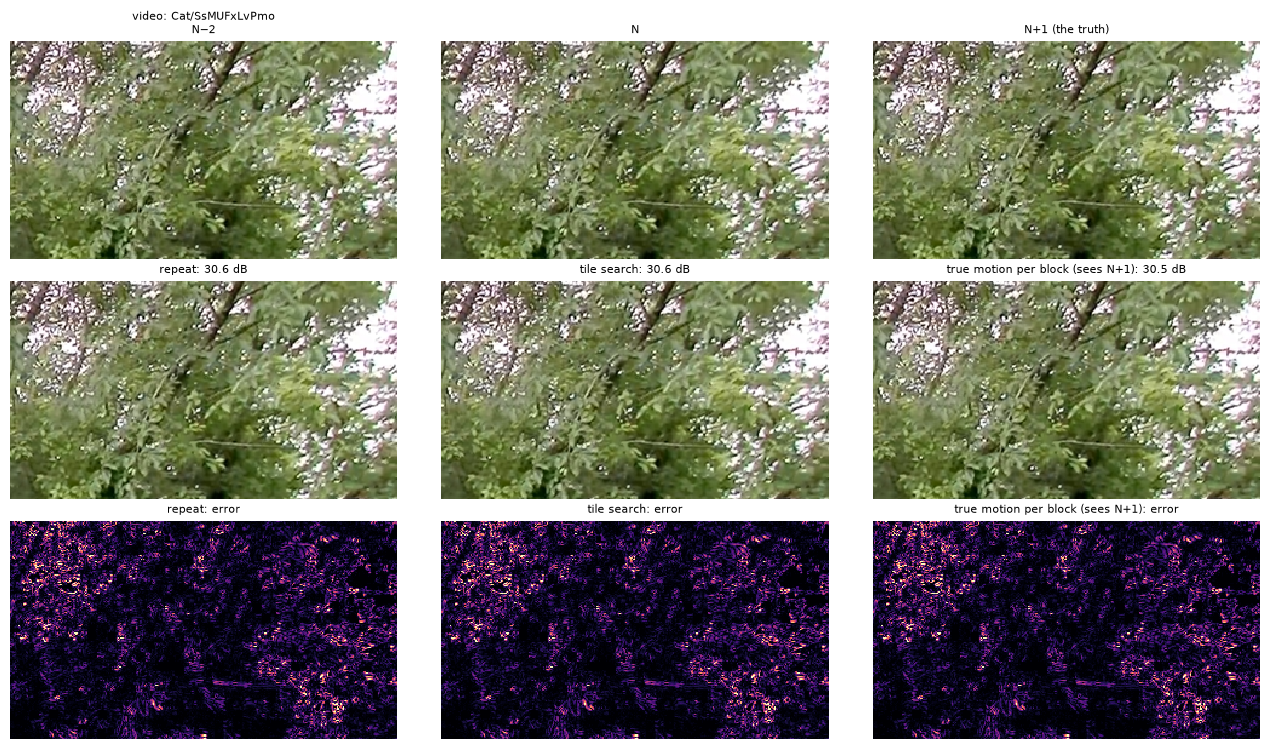

In [5]:
@torch.no_grad()
def example(kind_name):
    """The changed tile of a kind at the median of the tile search's score: its source and frames."""
    rows = moves[kind_name]
    index, n, t = (int(v) for v in rows[np.argmin(np.abs(rows[:, 1] - np.median(rows[:, 1]))), 8:11])
    source = sources[index]
    stream = clips.rebuild(source, manifest)
    layout, size = clips.plan(stream.shape[2], stream.shape[1])
    ix, iy, ox, oy, w, h = layout[t]
    window = stream[[n - RECEIVED, n, n + 1], iy:iy + size[0], ix:ix + size[1]][None]
    previous, current, target = to_tensor(window).unbind(1)
    return source, previous, current, target, (oy, ox, h, w)


for kind_name in KINDS:
    found = example(kind_name)
    if found is None:
        continue
    source, previous, current, target, box = found
    made = {"repeat": current, "tile search": search_model(previous, current),
            "true motion per block (sees N+1)": models.warp(current, block_truth.field(current, target))}
    y, x, h, w = box
    crop = lambda image: image[..., y:y + h, x:x + w]
    fig, axes = plt.subplots(3, 3, figsize=(13, 7.4))
    for ax, image, label in zip(axes[0], (previous, current, target), ("N−2", "N", "N+1 (the truth)")):
        show.picture(ax, crop(image), f"{kind_name}: {source.get('video', source['file'])}\n{label}" if label == "N−2" else label)
    for column, (name, image) in enumerate(made.items()):
        score = history.sample_wpsnr(crop(image), crop(target)).item()
        show.picture(axes[1][column], crop(image), f"{name}: {score:.1f} dB")
        show.error(axes[2][column], crop(image), crop(target), f"{name}: error")
    fig.tight_layout(pad=0.4)
    plt.show()

## What it says

- **The search is worth most where the picture moves as one.** On the changed validation tiles,
  repeat → the published search: photos +7.6 dB (95% over clips +4.5 to +10.1), drawn pages +4.6
  (+1.8 to +7.3), screens +1.8 (+0.1 to +3.8), video +0.7 (−1.0 to +1.6), drawn desktops +0.0. By
  rate: recordings at 24-30 fps 32.39 → 34.17, at 50-60 fps 30.13 → 30.85, drawn scenes 24.57 → 30.00.
- **How much of a kind's change is one motion**: a whole-tile motion of 1 px or more is behind 81% of
  the photos' changed tiles, 76% of the pages', 51% of video's, 32% of the desktops' and **26% of the
  screens'**. On a screen the rest is a window fading, a menu, text, a highlight - no copy of N makes
  it, and the median screen tile ("Examples") is a window fading out over the desktop, every method
  at the same 34.7 dB.
- **Where it is one motion, the search finds it about half the time**: it carries the true motion
  (0.75-1.25 times) on 58% of the photos' such tiles, 48% of the screens', 36% of video's, 35% of the
  pages' and 2% of the desktops'. It misses a motion past its reach (over 4 px a frame: 59% of the
  desktops', 50% of video's, 37% of the pages'), a scroll that starts after N, and a dragged window,
  which is part of a tile.
- **The recordings' motion is per block.** The true motion per 16 px block, found with N+1 in hand,
  reaches 37.79 dB on screens and 36.32 on video, against 34.88 and 32.51 for one motion per tile and
  the search's 34.14 and 30.86. 3DRS, a motion per block from the two frames, takes some of it on the
  changed tiles: screens 34.75, video 31.74 (+0.58 and +0.86 over its run's search), while losing on the
  drawn photos.
- **Repeated frames cost the recordings a sixth of their samples.** 17% of the screens' and of video's
  received frames are dropped because the frames around them repeat. Requiring every frame from N−2
  to N+2 to be new also removes the uneven timing that made the search carry half a motion - which is
  why the screens' gain here (+1.8) is larger than on the first set's screen recordings (+0.4).

So the drawn scenes are where one motion per tile is right, and the recordings where it is right only
for the part of their change that is motion at all - a quarter of a screen's, half of a video's - and
even there often as several motions in a tile.